# TP 2 - Séance 2
## Apprentissage profond appliqué aux images médicales

Équipe #0
- Nom, Prénom (Matricule)
- Nom, Prénom (Matricule)

In [1]:
import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.manifold import TSNE
from tqdm import tqdm
from collections import Counter

C:\Users\plber\anaconda3\envs\gbm8770\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from utils import get_dataloaders, get_embeddings, get_model_and_optimizer, train_epoch, validate


## Exercice 2.1: Exploration des données

Le jeu de données `dataset` est un objet de type [`DatasetDict`](https://huggingface.co/docs/datasets/main/en/package_reference/main_classes#datasets.DatasetDict) organisé comme un `dict` standard en Python, avec des entrées nommées `"train"` et `"test"` et qui contiennent des [`Dataset`](https://huggingface.co/docs/datasets/main/en/package_reference/main_classes#datasets.Dataset) - qui eux contiennent les images et leur label associé.

Vous pouvez interagir avec un `DatasetDict` essentiellement de la même manière qu'avec un `dict` (e.g. les méthodes `keys()`/`values()`/`items()`, aller chercher une entrée avec la notation par crochets `dataset["train"]`, etc.).

Pour interagir avec un `Dataset`, vous pouvez soit aller chercher un exemple donné (e.g. `dataset["train"][0]` qui est un `dict` qui contient une image et son label), soit aller chercher **tous** les labels/images du dataset (e.g. `list(dataset["train"]["label"])`).

<span style="color:red">**Attention!** Si vous essayez de charger toutes les images d'un coup, ça ne machera probablement pas car il y en a beaucoup trop pour la quantité de RAM qui est vraisemblablement disponible sur votre machine.
</span>

In [3]:
dataset = datasets.load_dataset("zacharielegault/Kermany2017-OCT")

# Certaines images sont encodées par erreur comme RGB. On les convertit en grayscale.
dataset["test"] = dataset["test"].map(lambda d: {"image": d["image"].convert("L")})

# Les images sont par défaut encodées en images PIL. On préfère des arrays Numpy qu'on connait bien.
dataset["train"] = dataset["train"].with_format("numpy")
dataset["test"] = dataset["test"].with_format("numpy")

**Q1.** Combien d'images y a-t-il dans chaque sous-ensemble du dataset?

In [4]:
a = len(dataset["train"])
b = len(dataset["test"])

print("Il y a ", a, " images d' entrainement et ", b, " images de test")

Il y a  108309  images d' entrainement et  1000  images de test


**Q2.** Quelles sont les classes représentées dans le dataset? Comment sont-elles représentées?

NB: Vous pouvez utiliser les méthodes `dataset["train"].features["label"].int2str(...)` et `dataset["train"].features["label"].str2int(...)` pour identifier les correspondances.

In [5]:
labels = dataset["train"].features["label"]

for i, name in enumerate(labels.names):
    print(f"Label {i} : {name}")

Label 0 : CNV
Label 1 : DME
Label 2 : DRUSEN
Label 3 : NORMAL


**Q3.** Quel nombre et proportion des images de chaque sous-ensemble appartient aux différentes classes? Affichez un histogramme de la distribution des classes pour chaque sous-ensemble.


train
CNV : 37205 images (34.35 %)
DME : 11348 images (10.48 %)
DRUSEN : 8616 images (7.96 %)
NORMAL : 51140 images (47.22 %)


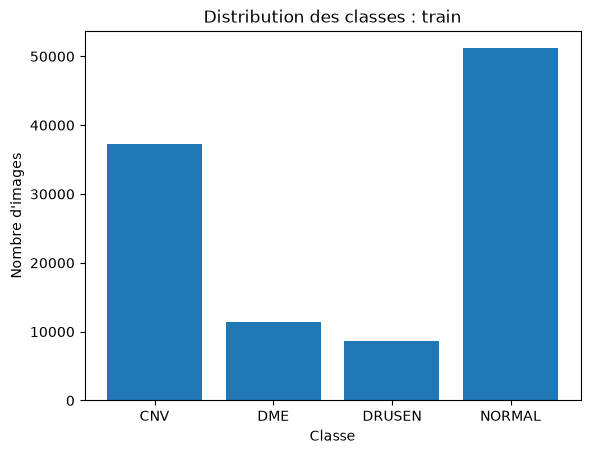


test
CNV : 250 images (25.00 %)
DME : 250 images (25.00 %)
DRUSEN : 250 images (25.00 %)
NORMAL : 250 images (25.00 %)


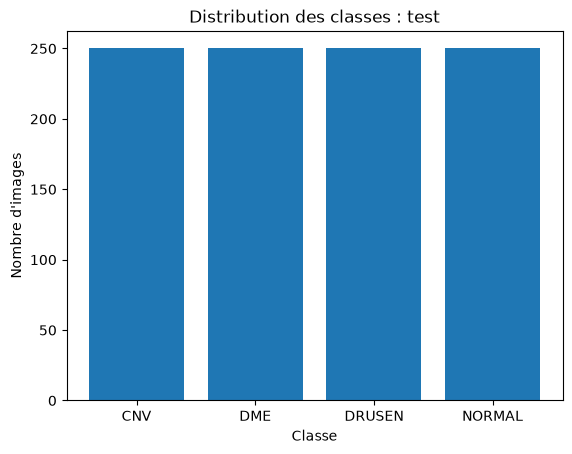

In [34]:
for split in ["train", "test"]:
    labels = dataset[split]["label"]
    counts = np.bincount(labels, minlength=4)
    proportions = counts / len(labels) * 100
    noms = dataset[split].features["label"].names

    print(f"\n{split}")
    for nom, count, prop in zip(noms, counts, proportions):
        print(f"{nom} : {count} images ({prop:.2f} %)")

    plt.bar(noms, counts)
    plt.title(f"Distribution des classes : {split}")
    plt.ylabel("Nombre d'images")
    plt.xlabel("Classe")
    plt.show()

**Q4.** Affichez 2 échantillons de chaque classe. Pour chaque image, affichez l'indice et la classe dans le titre. Décrivez les différences que vous observez entre les classes.

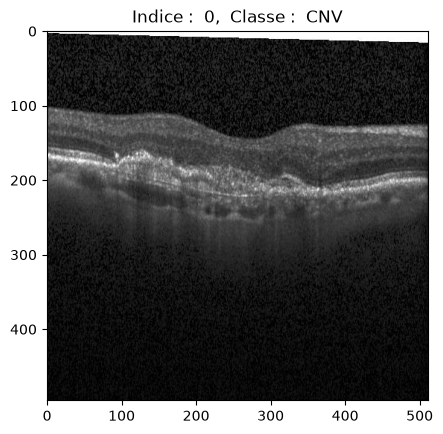

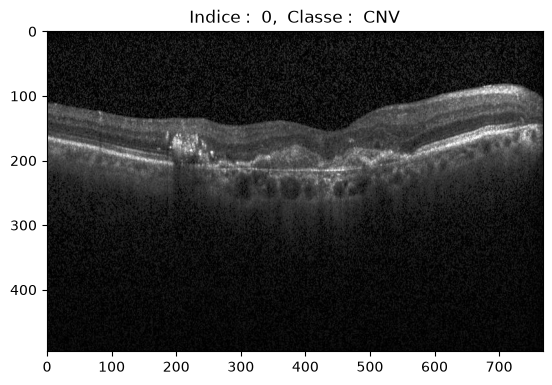

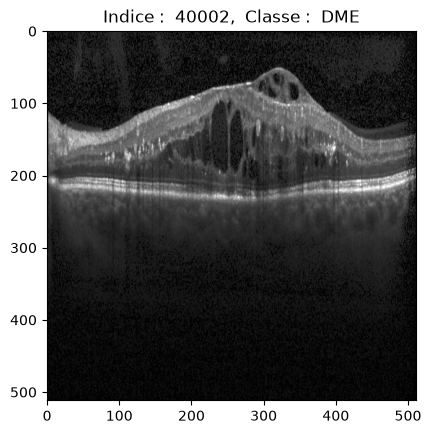

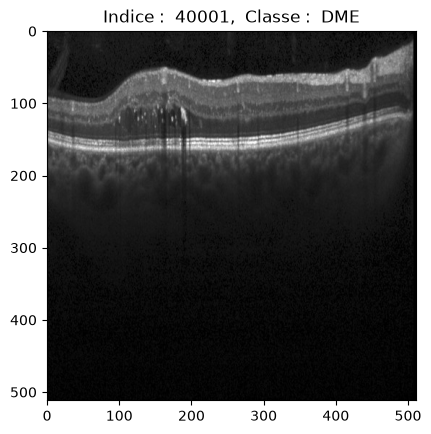

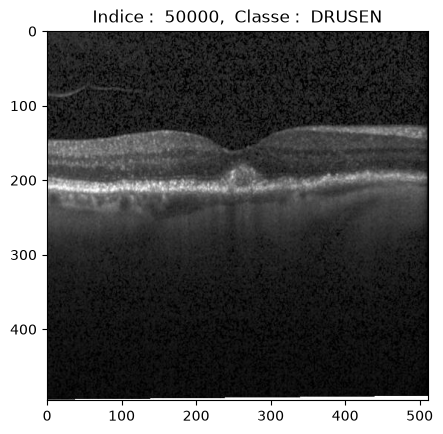

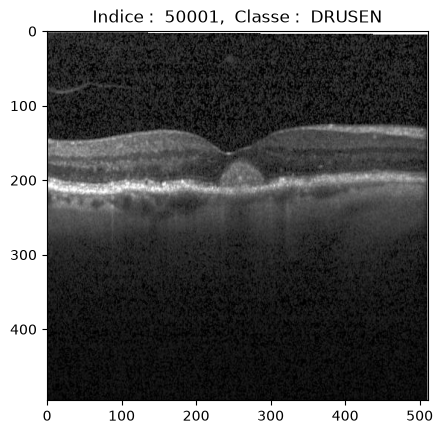

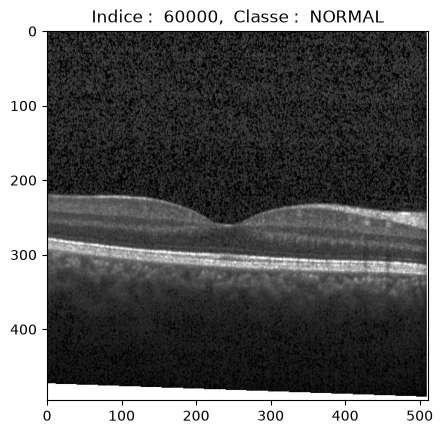

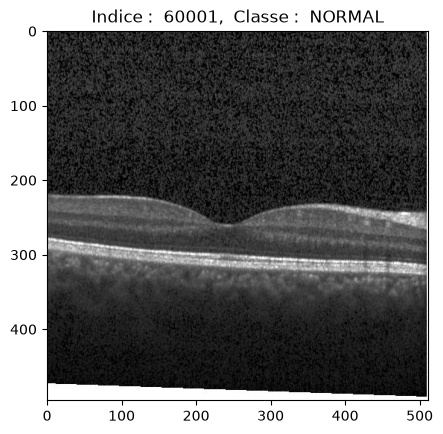

In [8]:
indice01 = 0
indice02 = 1
indice11 = 40002
indice12 = 40001
indice21 = 50000
indice22 = 50001
indice31 = 60000
indice32 = 60001
img01 = {"image":dataset["train"][indice01]["image"], "indice":indice01, "label":dataset["train"][indice01]["label"]}
img02 = {"image":dataset["train"][indice02]["image"], "indice":indice01, "label":dataset["train"][indice02]["label"]}
img11 = {"image":dataset["train"][indice11]["image"], "indice":indice11, "label":dataset["train"][indice11]["label"]}
img12 = {"image":dataset["train"][indice12]["image"], "indice":indice12, "label":dataset["train"][indice12]["label"]}
img21 = {"image":dataset["train"][indice21]["image"], "indice":indice21, "label":dataset["train"][indice21]["label"]}
img22 = {"image":dataset["train"][indice22]["image"], "indice":indice22, "label":dataset["train"][indice22]["label"]}
img31 = {"image":dataset["train"][indice31]["image"], "indice":indice31, "label":dataset["train"][indice31]["label"]}
img32 = {"image":dataset["train"][indice32]["image"], "indice":indice32, "label":dataset["train"][indice32]["label"]}
images = np.array([img01, img02, img11, img12, img21, img22, img31, img32])


for img in images:
    plt.imshow(img["image"], cmap="gray")
    indice = img["indice"]
    if img["label"]==0:
        classe="CNV"
    if img["label"]==1:
        classe="DME"
    if img["label"]==2:
        classe="DRUSEN"
    if img["label"]==3:
        classe="NORMAL"
    plt.title(f"Indice :  {indice},  Classe :  {classe}")
    plt.show()

CNV : ligne clair en dessous pas nette ni droite
DME : pas symétrique et pas droit
DRUSEN : boule blanchatre au centre
NORMAL : symétrique barre claire droite

**Q5.** Vous remarquerez que les images ne sont pas toutes de la même taille. Identifiez les tailles d'images et leur fréquence dans chaque sous-ensemble. Que pouvez-vous observer sur leur distribution? En quoi est-ce que des images de tailles différentes peut être un problème?

In [33]:
tailles0 = []
tailles1 = []
tailles2 = []
tailles3 = []

labels = dataset["train"]["label"]

for i in range(len(labels)):
    if labels[i] == 0:
        img = dataset["train"][i]["image"]
        tailles0.append(img.shape[:2])
    if labels[i] == 1:
        img = dataset["train"][i]["image"]
        tailles1.append(img.shape[:2])
    if labels[i] == 2:
        img = dataset["train"][i]["image"]
        tailles2.append(img.shape[:2])
    if labels[i] == 3:
        img = dataset["train"][i]["image"]
        tailles3.append(img.shape[:2])

frequences0 = Counter(tailles0)
frequences1 = Counter(tailles1)
frequences2 = Counter(tailles2)
frequences3 = Counter(tailles3)

KeyboardInterrupt: 

In [ ]:
frequences=np.array([frequences0, frequences1, frequences2, frequences3])
print(frequences)

Les images possèdent des dimensions variables, particulièrement au niveau de leur largeur. Cette hétérogénéité pose problème pour l'entraînement d'un réseau de neurones, notamment parce qu'il faut pouvoir regrouper les images dans des tenseurs de dimensions identiques.
Le fichier utils.py résout ce problème en appliquant un redimensionnement à 256 × 256, suivi d'un recadrage à 224 × 224 pixels.
Cependant, ces transformations peuvent entraîner une perte d'informations ou une déformation des structures anatomiques.

## Exercice 2.2: Entraînement d'un modèle de classification

**Q1**. Créez un modèle qui n'a pas été pré-entraîné (utilisez la valeur par défaut de `pretrained=False`). Calculez la _loss_ initiale du modèle sur 10% des données d'entraînement. Est-ce que la _loss_ initiale est bien ce à quoi vous vous attendiez?

In [9]:
train_loader, val_loader, test_loader = get_dataloaders(dataset, batch_size=64, train_subset=0.1)

In [10]:
model, optimizer = get_model_and_optimizer(pretrained=False)
loss, accuracy = validate(model, train_loader)

print("Loss initiale :", loss)
print("Loss théorique :", np.log(4))

Loss initiale : 1.386294364651133
Loss théorique : 1.3862943611198906


La loss initiale est la même que la valeur théorique, pour l'instant pas de problème

**Q2**. Entraînez votre modèle sur 10% des données d'entraînement (20 époques devraient suffire). Affichez la courbe d'évolution de votre erreur (_loss_) d'entraînement. Au long de votre entraînement, validez la performance de votre modèle sur l'ensemble de validation et affichez la _loss_ et l'_accuracy_ en fonction de l'époque.

Faites le suivi de l'_accuracy_ et identifiez la plus haute valeur obtenue au cours de l'entraînement. Faites une sauvegarde du modèle lorsque vous obtenez cette meilleure _accuracy_.

N.B.: Pour cette question, vous n'avez pas besoin de faire une validation à chaque époque. Vous pouvez choisir un intervalle plus grand (e.g. toutes les 2 époques) pour diminuer le temps de calcul.

In [13]:
epochs = []
val_losses = []
val_accuracies = []
loss_total = []
best_accuracy = 0

for epoch in range(20):
    # Entraînement
    losses = train_epoch(model, train_loader, optimizer)
    loss_total.append(np.mean(losses))
    print(epoch, np.mean(losses))
          
    # Validation toutes les 2 époques
    if (epoch + 1) % 2 == 0:
        val_loss, val_accuracy = validate(model, val_loader)

        epochs.append(epoch + 1)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), "best_model.pt")

0 0.30485052994874695


1 0.2228002707873072


2 0.16285129582150754


3 0.11190088008825454


4 0.08647654142508411


5 0.07112179537916914


... (10 outputs left out)

16 0.03227061399451012


17 0.021806846460817753


18 0.03458464793790051


19 0.03357816360108497


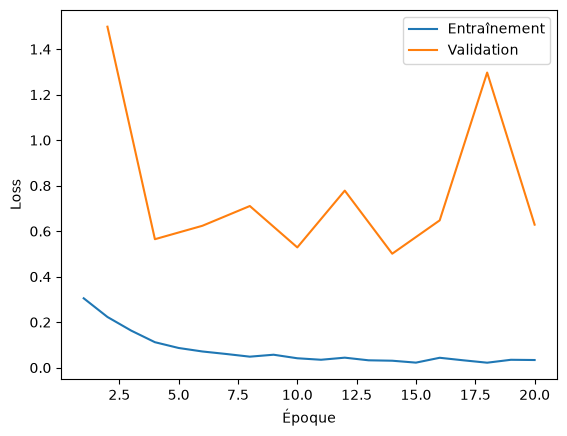

In [14]:
plt.plot(range(1, 21), loss_total, label="Entraînement")
plt.plot(epochs, val_losses, label="Validation")

plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.show()

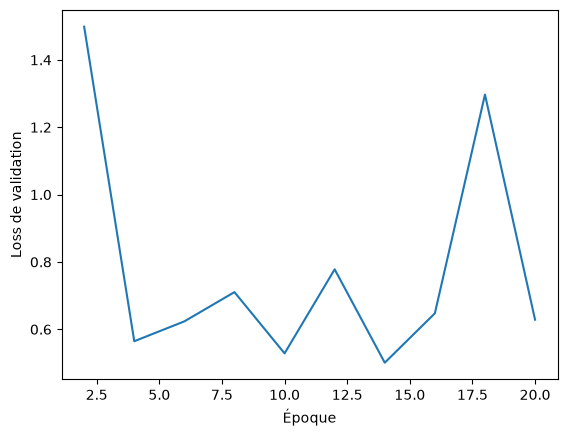

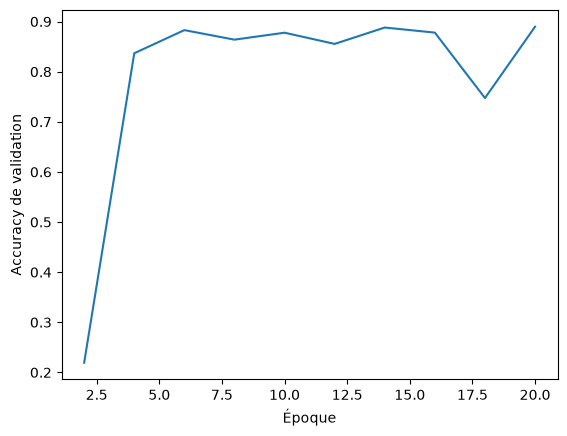

In [15]:
plt.plot(epochs, val_losses)
plt.xlabel("Époque")
plt.ylabel("Loss de validation")
plt.show()

plt.plot(epochs, val_accuracies)
plt.xlabel("Époque")
plt.ylabel("Accuracy de validation")
plt.show()

## Apprentissage par transfert

**Q1**. Étant données les différences marquées entre les caractéristiques des images d'ImageNet (des chats, des chiens, des autobus, des spatules, etc.) et les images OCT de la rétine, pensez-vous qu'utiliser un modèle pré-entraîné sur ImageNet va aider vos performances de classification? Expliquez votre raisonnement.

un modèle pré-entraîné pourrait apprendre plus rapidement et obtenir de meilleures performances, même si les images OCT sont très différentes des images d'ImageNet.

**Q2**. Affinez pendant au moins 10 époques un modèle pré-entraîné. Créez le en utilisant l'argument `pretrained=True`. Durant l'entraînement du modèle, faites une sauvegarde du modèle lorsque vous obtenez la meilleure _accuracy_. Affichez les courbes d'évolution de votre _loss_ d'entraînement, et de votre _loss_ et _accuracy_ de validation.

In [16]:
model_pretrained, optimizer_pretrained = get_model_and_optimizer(pretrained=True)

In [17]:
epochs = []
val_losses = []
val_accuracies = []
loss_total = []
best_accuracy = 0

for epoch in range(20):
    # Entraînement
    losses = train_epoch(model_pretrained, train_loader, optimizer_pretrained)
    loss_total.append(np.mean(losses))
    print(epoch, np.mean(losses))
          
    # Validation toutes les 2 époques
    if (epoch + 1) % 2 == 0:
        val_loss, val_accuracy = validate(model_pretrained, val_loader)

        epochs.append(epoch + 1)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)
    
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model_pretrained.state_dict(), "best_model_pretrained.pt")

0 0.25967598822176086


1 0.0954197428727187


2 0.057569318798064074


3 0.029360989165804725


4 0.023855342585391


5 0.026445750040631245


... (10 outputs left out)

16 0.0028010679836246123


17 0.018742266003337473


18 0.007273489253471464


19 0.010557653163949745


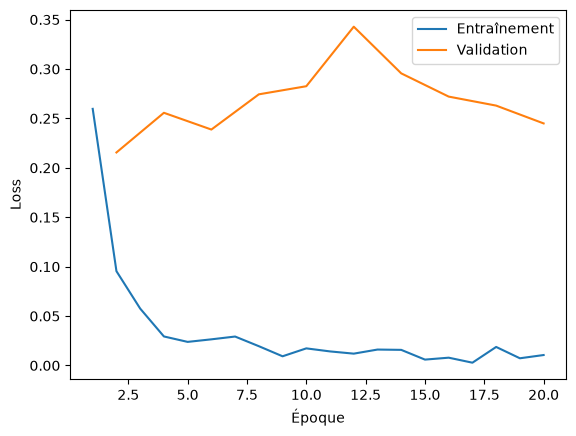

In [18]:
plt.plot(range(1, 21), loss_total, label="Entraînement")
plt.plot(epochs, val_losses, label="Validation")

plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.show()

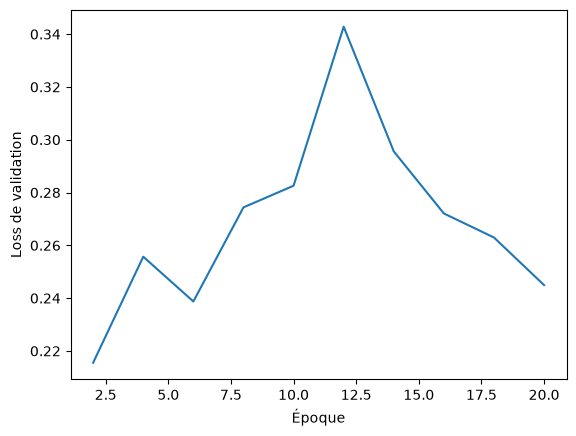

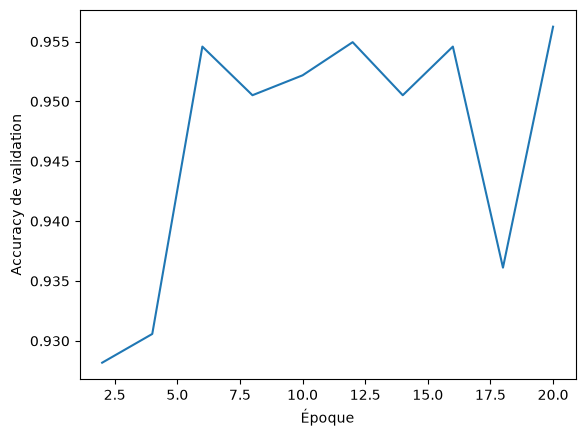

In [19]:
plt.plot(epochs, val_losses)
plt.xlabel("Époque")
plt.ylabel("Loss de validation")
plt.show()

plt.plot(epochs, val_accuracies)
plt.xlabel("Époque")
plt.ylabel("Accuracy de validation")
plt.show()

**Q3.** Comparez les performances de votre modèle pré-entraîné avec celles de votre modèle non pré-entraîné. Qu'en concluez-vous?

On observe :
- Loss d'entraînement : elle diminue fortement, d'environ 0,26 à 0,005.
- Loss de validation : elle fluctue entre 0,22 et 0,37, ce qui suggère un certain surapprentissage.
- Accuracy de validation : elle progresse globalement et atteint environ 96,3 % à l'époque 20.
le modèle pré-entraîné fait donc mieux que le modèle initialisé aléatoirement, qui atteignait environ 91,8 % d'accuracy.

Le modèle pré-entraîné sur ImageNet obtient donc de meilleures performances que le modèle initialisé aléatoirement, dont l'accuracy maximale était d'environ 91,8 %, soit une amélioration de 4,5 points de pourcentage.

## Évaluation finale

**Q1**. Évaluez votre meilleur modèle sur l'ensemble de test. Affichez la _loss_ et l'_accuracy_ finale.

In [20]:
best_model, optimizer = get_model_and_optimizer(pretrained=False)

weights = torch.load("best_model_pretrained.pt", map_location="cpu", weights_only=True)
best_model.load_state_dict(weights)


train_loader, val_loader, test_loader = get_dataloaders(dataset, batch_size=64, train_subset=1)

# Évaluer le modèle sur les données de TEST
test_loss, test_accuracy = validate(best_model, test_loader)

print("Loss de test :", test_loss)
print("Accuracy de test :", test_accuracy)

Loss de test : 0.34587413554266094
Accuracy de test : 0.933


**Q2**. Commentez les performances de votre modèle sur l'ensemble de test et comparez-les à celles obtenues sur l'ensemble de validation.

Le modèle pré-entraîné obtient une accuracy de 93,3 % et une loss de 0,346 sur l'ensemble de test, contre une accuracy maximale de validation d'environ 96,3 % et une loss d'environ 0,256 à la dernière époque.
Cette diminution des performances suggère une capacité de généralisation légèrement inférieure à celle observée lors de la validation. Elle peut notamment s'expliquer par un certain surapprentissage ou par des différences entre les distributions des images de validation et de test.
Néanmoins, le modèle conserve de bonnes performances de classification sur des données indépendantes, avec une accuracy supérieure à 93 %.


**Q3**. Pourquoi est-il important de maintenir un ensemble de test séparé de l'ensemble de validation? Que se passerait-il si on n'avait que deux ensembles (entraînement et validation/test) plutôt que trois (entraînement, validation, test)?

Il est important de séparer les ensembles de validation et de test, car les données de validation servent à sélectionner le meilleur modèle et éventuellement à ajuster ses hyperparamètres. Le modèle peut donc être indirectement optimisé pour ces données.
Si nous utilisions le même ensemble pour la validation et le test, nous risquerions de surestimer ses performances sur de nouvelles images.
Un ensemble de test indépendant permet d'évaluer plus objectivement la capacité de généralisation du modèle et de détecter d'éventuels problèmes de surapprentissage.

**Q4**. Au sein de l’ensemble de test, identifiez

<!-- | Une image CNV correctement identifiée comme CNV | Une image CNV incorrectement identifiée comme DME | 
 -->


| Une image CNV correctement identifiée comme CNV | Une image CNV incorrectement identifiée comme DME | Une image CNV incorrectement identifiée comme Drusen | Une image CNV incorrectement identifiée comme normale |
|---|---|---|---|
| Une image DME incorrectement identifiée comme CNV | Une image DME correctement identifiée comme DME | Une image DME incorrectement identifiée comme Drusen | Une image DME incorrectement identifiée comme normale |
| Une image Drusen incorrectement identifiée comme CNV | Une image Drusen incorrectement identifiée comme DME | Une image Drusen correctement identifiée comme Drusen | Une image Drusen incorrectement identifiée comme normale |
| Une image normale incorrectement identifiée comme CNV | Une image normale incorrectement identifiée comme DME | Une image normale incorrectement identifiée comme Drusen | Une image normale correctement identifiée comme normale |

In [21]:
test_loss, test_accuracy, predictions = validate(best_model, test_loader, return_preds=True)

In [22]:
true_labels = dataset["test"]["label"]
erreurs = []
print("liste des listes avec contradictions")
for i in range(len(predictions)):
    if true_labels[i] == 0 and predictions[i] == 1:
        print("Image trouvée pour vrai 0 et prédit 1 :", i)
        erreurs.append(i)
    if true_labels[i] == 0 and predictions[i] == 2:
        print("Image trouvée pour vrai 0 et prédit 2 :", i)
        erreurs.append(i)
    if true_labels[i] == 0 and predictions[i] == 3:
        print("Image trouvée pour vrai 0 et prédit 3 :", i)
        erreurs.append(i)
    if true_labels[i] == 1 and predictions[i] == 0:
        print("Image trouvée pour vrai 1 et prédit 0 :", i)
        erreurs.append(i)
    if true_labels[i] == 1 and predictions[i] == 2:
        print("Image trouvée pour vrai 1 et prédit 2 :", i)
        erreurs.append(i)
    if true_labels[i] == 1 and predictions[i] == 3:
        print("Image trouvée pour vrai 1 et prédit 3 :", i)
        erreurs.append(i)
    if true_labels[i] == 2 and predictions[i] == 0:
        print("Image trouvée pour vrai 2 et prédit 0 :", i)
        erreurs.append(i)
    if true_labels[i] == 2 and predictions[i] == 1:
        print("Image trouvée pour vrai 2 et prédit 1 :", i)
        erreurs.append(i)
    if true_labels[i] == 2 and predictions[i] == 3:
        print("Image trouvée pour vrai 2 et prédit 3 :", i)
        erreurs.append(i)
    if true_labels[i] == 3 and predictions[i] == 0:
        print("Image trouvée pour vrai 3 et prédit 0 :", i)
        erreurs.append(i)
    if true_labels[i] == 3 and predictions[i] == 1:
        print("Image trouvée pour vrai 3 et prédit 1 :", i)
        erreurs.append(i)
    if true_labels[i] == 3 and predictions[i] == 2:
        print("Image trouvée pour vrai 3 et prédit 2 :", i)
        erreurs.append(i)

liste des listes avec contradictions
Image trouvée pour vrai 0 et prédit 1 : 14
Image trouvée pour vrai 0 et prédit 1 : 19
Image trouvée pour vrai 0 et prédit 1 : 57
Image trouvée pour vrai 0 et prédit 1 : 160
Image trouvée pour vrai 0 et prédit 1 : 221
Image trouvée pour vrai 2 et prédit 0 : 515
Image trouvée pour vrai 2 et prédit 3 : 519
Image trouvée pour vrai 2 et prédit 3 : 520
Image trouvée pour vrai 2 et prédit 0 : 524
Image trouvée pour vrai 2 et prédit 1 : 528
Image trouvée pour vrai 2 et prédit 3 : 531
Image trouvée pour vrai 2 et prédit 0 : 535
Image trouvée pour vrai 2 et prédit 0 : 543
Image trouvée pour vrai 2 et prédit 0 : 545
Image trouvée pour vrai 2 et prédit 0 : 546
Image trouvée pour vrai 2 et prédit 1 : 547
Image trouvée pour vrai 2 et prédit 1 : 552
Image trouvée pour vrai 2 et prédit 0 : 559
Image trouvée pour vrai 2 et prédit 0 : 563
Image trouvée pour vrai 2 et prédit 0 : 567
Image trouvée pour vrai 2 et prédit 0 : 568
Image trouvée pour vrai 2 et prédit 0 : 57

Ce code permet d'obtenir une liste de label d'image test qui sont mal prédites. On constate que certaine combinaisons n'existent pas, dans ces le modèle arrive à bien prédire, il semble surtout avoir du mal à prédire 2

In [24]:
print("exemples de bonnes prédictions pour chaque cas")
for i in range(len(predictions)):
    if true_labels[i] == 0 and predictions[i] == 0:
        print("Image trouvée pour vrai 0 et prédit 0 :", i)
        break
for i in range(len(predictions)):
    if true_labels[i] == 1 and predictions[i] == 1:
        print("Image trouvée pour vrai 1 et prédit 1 :", i)
        break
for i in range(len(predictions)):
    if true_labels[i] == 2 and predictions[i] == 2:
        print("Image trouvée pour vrai 2 et prédit 2 :", i)
        break

for i in range(len(predictions)):
    if true_labels[i] == 3 and predictions[i] == 3:
        print("Image trouvée pour vrai 3 et prédit 3 :", i)
        break

exemples de bonnes prédictions pour chaque cas
Image trouvée pour vrai 0 et prédit 0 : 0
Image trouvée pour vrai 1 et prédit 1 : 250
Image trouvée pour vrai 2 et prédit 2 : 500
Image trouvée pour vrai 3 et prédit 3 : 750


In [25]:
indice_dic = {"01":19, "20":515, "21":639, "23":715, "31":802, "00":0, "11":250, "22":500, "33":750}

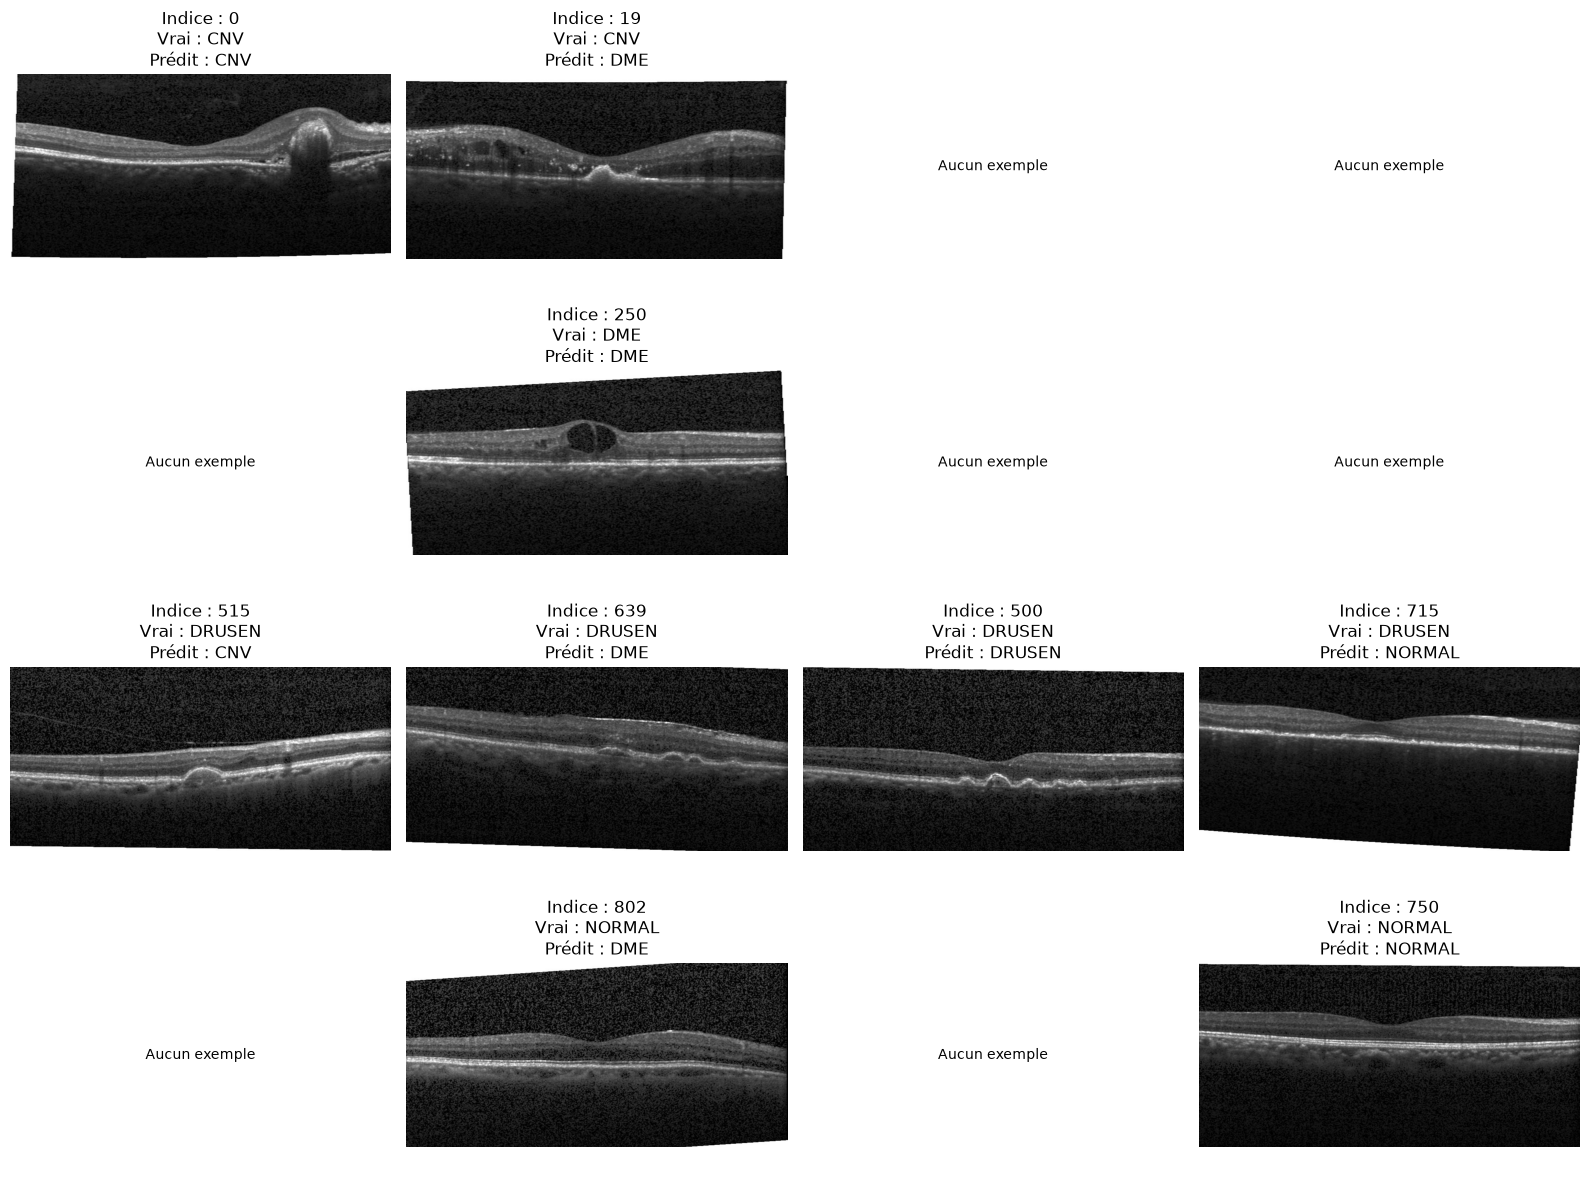

In [26]:
noms = dataset["test"].features["label"].names

fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for vrai in range(4):
    for predit in range(4):

        ax = axes[vrai, predit]
        cle = f"{vrai}{predit}"

        if cle in indice_dic:
            indice = indice_dic[cle]
            img = dataset["test"][indice]["image"]

            ax.imshow(img, cmap="gray")
            ax.set_title(
                f"Indice : {indice}\n"
                f"Vrai : {noms[vrai]}\n"
                f"Prédit : {noms[predit]}"
            )
        else:
            ax.text(0.5, 0.5, "Aucun exemple",
                    ha="center", va="center")

        ax.axis("off")

plt.tight_layout()
plt.show()

**Q5**. Au vu des performances de votre meilleur modèle sur les données de test, seriez-vous à l'aise d'intégrer ce modèle dans des protocoles cliniques pour aider au diagnostic? Justifiez votre réponse.

Malgré une accuracy de 93,3 % sur les données de test, il serait prématuré d'intégrer directement ce modèle dans un protocole clinique sans validation supplémentaire.
En effet, certaines erreurs de classification peuvent avoir des conséquences importantes, notamment les faux négatifs qui risquent de retarder la prise en charge d'un patient malade. Les faux positifs peuvent également conduire à des examens inutiles.
On remarque notamment que le modèle rencontre davantage de difficultés avec la classe Drusen, ce qui montre que ses performances ne sont pas homogènes entre les différentes pathologies.
Le modèle pourrait être intéressant comme outil d'aide au diagnostic, mais il nécessiterait des évaluations supplémentaires sur des données indépendantes et diversifiées, ainsi qu'une supervision médicale avant toute utilisation clinique.

## Visualisation de l'espace latent

**Q1**. Utilisez la fonction `get_embeddings` pour extraire les _vecteurs latents_ des images de l'ensemble de test issus
1. d'un modèle aléatoirement initialisé;
2. d'un modèle pré-entraîné sur ImageNet, mais non affiné;
3. de votre modèle entraîné (sans pré-entraînement);
4. de votre modèle affiné (avec pré-entraînement).

In [27]:
model1, optimizer1 = get_model_and_optimizer(pretrained=False)
embeddings1 = get_embeddings(model1, test_loader)

In [28]:
model2, optimizer2 = get_model_and_optimizer(pretrained=True)
embeddings2 = get_embeddings(model2, test_loader)

In [29]:
model3, optimizer3 = get_model_and_optimizer(pretrained=False)
weights = torch.load("best_model.pt", map_location="cpu", weights_only=True)
model3.load_state_dict(weights)
embeddings3 = get_embeddings(model3, test_loader)

In [30]:
model4, optimizer4 = get_model_and_optimizer(pretrained=False)
weights = torch.load("best_model_pretrained.pt", map_location="cpu", weights_only=True)
model4.load_state_dict(weights)
embeddings4 = get_embeddings(model4, test_loader)

In [31]:
print(embeddings1.shape)
print(embeddings2.shape)
print(embeddings3.shape)
print(embeddings4.shape)

torch.Size([1000, 960])
torch.Size([1000, 960])
torch.Size([1000, 960])
torch.Size([1000, 960])


**Q2**. Pour chacun des trois ensembles de vecteurs latents obtenus à la question précédente, utilisez la méthode t-SNE pour réduire la dimensionnalité des vecteurs à 2D. Affichez les résultats dans un graphique de dispersion (_scatter plot_), où chaque point représente une image, et où la couleur du point indique la classe de l'image. Commentez vos observations.

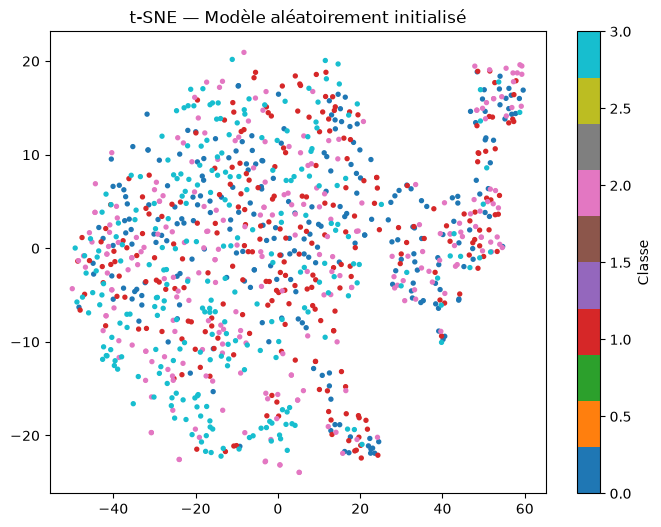

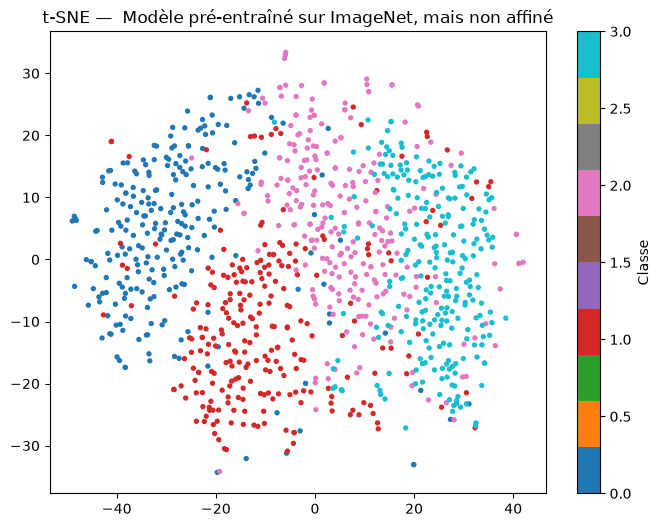

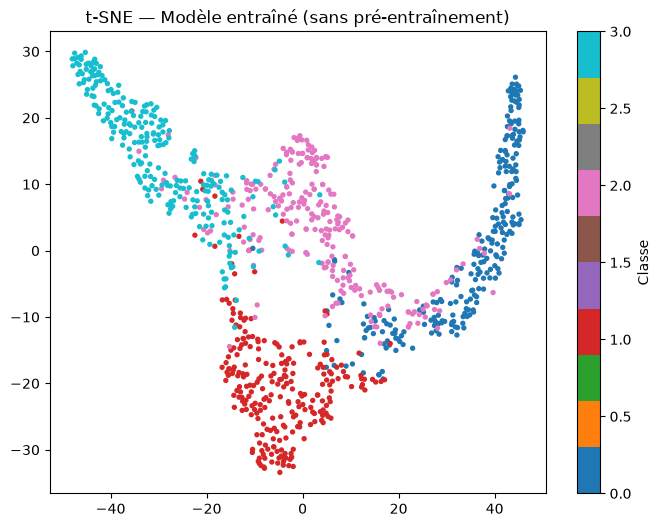

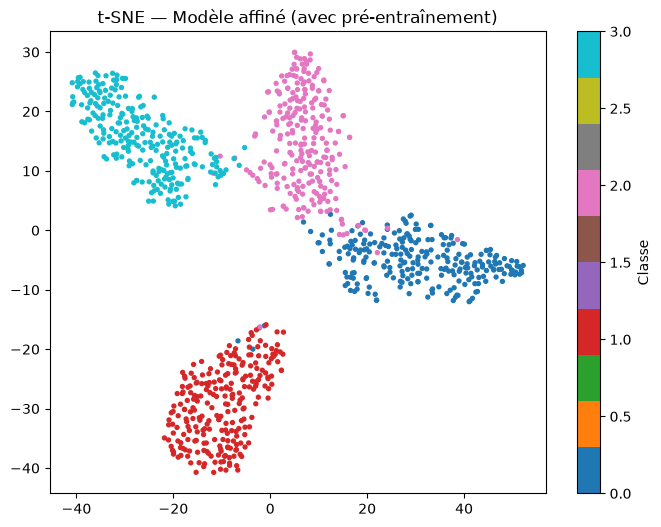

In [32]:
tsne = TSNE(n_components=2, random_state=42)
projection1 = tsne.fit_transform(embeddings1.numpy())
projection2 = tsne.fit_transform(embeddings2.numpy())
projection3 = tsne.fit_transform(embeddings3.numpy())
projection4 = tsne.fit_transform(embeddings4.numpy())
labels = np.array(dataset["test"]["label"])

plt.figure(figsize=(8, 6))
plt.scatter(projection1[:, 0], projection1[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(label="Classe")
plt.title("t-SNE — Modèle aléatoirement initialisé")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(projection2[:, 0], projection2[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(label="Classe")
plt.title("t-SNE —  Modèle pré-entraîné sur ImageNet, mais non affiné")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(projection3[:, 0], projection3[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(label="Classe")
plt.title("t-SNE — Modèle entraîné (sans pré-entraînement)")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(projection4[:, 0], projection4[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(label="Classe")
plt.title("t-SNE — Modèle affiné (avec pré-entraînement)")
plt.show()

Les projections t-SNE montrent une évolution des représentations latentes selon l'entraînement des modèles.
Le modèle initialisé aléatoirement ne parvient pas à distinguer clairement les quatre classes, qui sont fortement mélangées dans l'espace latent.
Le modèle pré-entraîné sur ImageNet, mais non affiné, présente une meilleure organisation des données, bien que les différentes classes restent partiellement mélangées.
Après entraînement sur les images OCT, les classes sont beaucoup mieux séparées. Cette séparation est particulièrement visible pour le modèle pré-entraîné puis affiné, qui présente des groupes plus distincts et moins de chevauchements.
Ces résultats suggèrent que le pré-entraînement sur ImageNet permet d'obtenir des caractéristiques visuelles pertinentes, ensuite adaptées aux images médicales durant le fine-tuning. Cette observation est cohérente avec les meilleures performances de classification obtenues par le modèle pré-entraîné.
Il faut néanmoins garder à l'esprit que t-SNE réduit les représentations de 960 à 2 dimensions et ne conserve donc pas toute l'information de l'espace latent.